# Who should we try to keep? — Customer churn prediction & value-based retention targeting

**Business question.** An online wholesaler/gift retailer has a limited retention budget for next quarter.
*Which customers should the retention campaign target to protect the most revenue?*

This notebook goes end-to-end, from raw transactions to a recommendation that a marketing team can act on:

1. **Data preparation** – clean ~1M raw invoice lines (duplicates, returns, missing customer IDs, non-product codes).
2. **Exploration** – seasonality, purchase frequency and revenue concentration, used to *justify* the churn definition.
3. **Churn definition & temporal design** – rolling snapshots so the model never sees the future (no leakage).
4. **Modeling** – a simple rule baseline vs. Logistic Regression vs. LightGBM, validated on a later, unseen period.
5. **Explainability** – SHAP: *why* each customer is at risk.
6. **From probabilities to decisions** – combine churn risk with customer value (CLV) into *expected revenue at risk*,
   simulate a campaign with a budget and compare targeting strategies.
7. **Segmentation & next best action** – a risk × value matrix with one action per segment.

> **Data:** [Online Retail II, UCI ML Repository](https://archive.ics.uci.edu/dataset/502/online+retail+ii) —
> all transactions of a UK-based online retailer between 01/12/2009 and 09/12/2011.

## 0. Setup

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import lightgbm as lgb
import shap
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.3f}".format)
RANDOM_STATE = 42

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "online_retail_II.xlsx"
PROCESSED = ROOT / "data" / "processed" / "online_retail_II.parquet"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Chart style: recessive axes/grid, a small fixed categorical order, text in neutral ink
BLUE, ORANGE, AQUA, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#9a9993", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK, "lines.linewidth": 2, "font.size": 10,
})

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


The raw file is an Excel workbook with one sheet per year. Reading it takes a few minutes, so the first run
converts it to Parquet (loads in < 1 s afterwards).

In [2]:
if not PROCESSED.exists():
    sheets = pd.read_excel(RAW, sheet_name=None, engine="openpyxl")
    raw = pd.concat(sheets.values(), ignore_index=True)
    for c in ["Invoice", "StockCode", "Country"]:
        raw[c] = raw[c].astype(str)
    raw["Description"] = raw["Description"].astype("string")
    PROCESSED.parent.mkdir(parents=True, exist_ok=True)
    raw.to_parquet(PROCESSED, index=False)

raw = pd.read_parquet(PROCESSED).rename(columns={"Customer ID": "CustomerID"})
print(f"{len(raw):,} rows | {raw.InvoiceDate.min():%Y-%m-%d} → {raw.InvoiceDate.max():%Y-%m-%d}")
raw.head()

1,067,371 rows | 2009-12-01 → 2011-12-09


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,"13,085.000",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,"13,085.000",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,"13,085.000",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,"13,085.000",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,"13,085.000",United Kingdom


## 1. Data preparation

Raw transactional data is never model-ready. The checks below quantify each issue before fixing it:

| Issue | Why it matters | Decision |
|---|---|---|
| Exact duplicate rows | The two yearly sheets **overlap on 1–9 Dec 2010**, so those invoices appear twice | Drop |
| Missing `CustomerID` | Guest checkouts can't be tracked over time → can't churn | Exclude from customer analysis |
| Invoices starting with `C` | Cancellations / returns | Keep separately → `return_rate` feature |
| Non-product codes (`POST`, `M`, `BANK CHARGES`, …) | Postage, manual adjustments, fees — not customer demand | Exclude |
| Price ≤ 0 or quantity ≤ 0 | Free samples, stock corrections | Exclude |

In [3]:
NON_PRODUCT = {"POST", "DOT", "M", "C2", "D", "S", "BANK CHARGES", "ADJUST", "ADJUST2", "AMAZONFEE",
               "CRUK", "PADS", "B", "TEST001", "TEST002"}

df = raw.copy()
quality = {
    "Raw rows": len(df),
    "Exact duplicates": df.duplicated().sum(),
    "Missing CustomerID": df.CustomerID.isna().sum(),
    "Cancellation lines": df.Invoice.str.startswith("C").sum(),
    "Non-product codes": df.StockCode.isin(NON_PRODUCT).sum(),
    "Price <= 0": (df.Price <= 0).sum(),
}
display(pd.Series(quality, name="rows").to_frame().style.format("{:,}"))

df = df.drop_duplicates()
df = df[df.CustomerID.notna() & ~df.StockCode.isin(NON_PRODUCT)].copy()
df["CustomerID"] = df.CustomerID.astype(int)
df["Revenue"] = df.Quantity * df.Price
df["is_cancel"] = df.Invoice.str.startswith("C")

sales = df[~df.is_cancel & (df.Quantity > 0) & (df.Price > 0)].copy()
returns = df[df.is_cancel].copy()

print(f"Clean sales lines: {len(sales):,} | customers: {sales.CustomerID.nunique():,} | "
      f"invoices: {sales.Invoice.nunique():,} | revenue: £{sales.Revenue.sum()/1e6:.1f}M")

,rows
Raw rows,"1,067,371"
Exact duplicates,"34,335"
Missing CustomerID,"243,007"
Cancellation lines,"19,494"
Non-product codes,"5,825"
Price <= 0,"6,207"


Clean sales lines: 776,579 | customers: 5,852 | invoices: 36,594 | revenue: £17.1M


## 2. Exploratory analysis — what does "normal" customer behaviour look like?

The goal of the EDA here is not to describe everything, but to answer the questions that shape the model:
*Is there seasonality? How often do customers buy? Is value concentrated?*

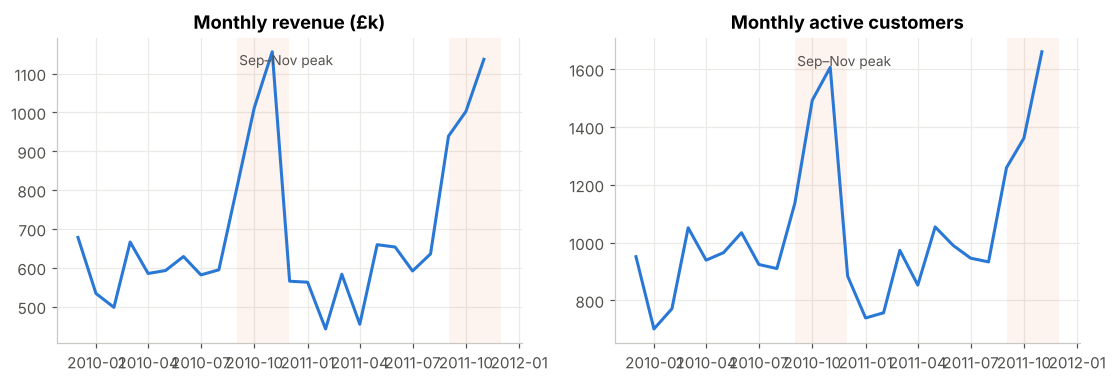

In [4]:
monthly = (sales.set_index("InvoiceDate")
                .resample("MS").agg(revenue=("Revenue", "sum"), customers=("CustomerID", "nunique")))
monthly = monthly.iloc[:-1]  # Dec 2011 only has 9 days

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(monthly.index, monthly.revenue / 1e3, color=BLUE)
axes[0].set_title("Monthly revenue (£k)")
axes[1].plot(monthly.index, monthly.customers, color=BLUE)
axes[1].set_title("Monthly active customers")
for ax in axes:
    for yr in (2010, 2011):
        ax.axvspan(pd.Timestamp(f"{yr}-09-01"), pd.Timestamp(f"{yr}-11-30"), color=ORANGE, alpha=0.08, lw=0)
    ax.text(pd.Timestamp("2010-09-05"), ax.get_ylim()[1] * 0.97, "Sep–Nov peak", color=INK, fontsize=9, va="top")
fig.savefig(FIG / "01_seasonality.png"); plt.show()

**Strong Q4 seasonality** (gift products bought by retailers ahead of Christmas): revenue and active customers roughly
double in Sep–Nov. Consequence for the model: *the churn rate depends on the season of the prediction window*, so
(a) the model gets a seasonal feature and (b) we test on the same season we would deploy in.

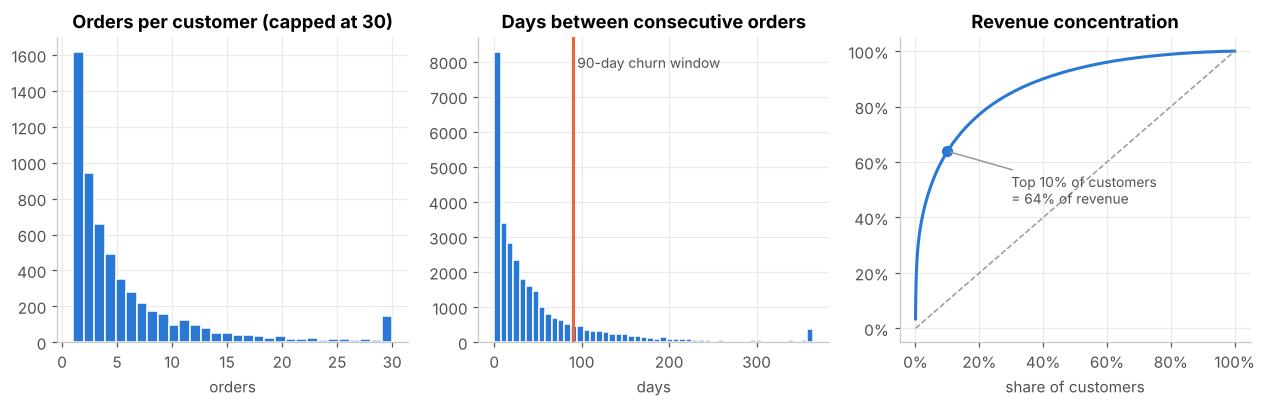

One-time buyers: 27.6% | median orders/customer: 3
Days between orders — median: 25, 80th percentile: 77, 90th: 135


In [5]:
orders = (sales.groupby(["CustomerID", "Invoice"]).agg(date=("InvoiceDate", "min"), value=("Revenue", "sum"))
               .reset_index().sort_values(["CustomerID", "date"]))
orders_per_cust = orders.groupby("CustomerID").size()
gaps = orders.groupby("CustomerID").date.diff().dt.days.dropna()
cust_rev = orders.groupby("CustomerID").value.sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(orders_per_cust.clip(upper=30), bins=30, color=BLUE, edgecolor="white", linewidth=1)
axes[0].set_title("Orders per customer (capped at 30)"); axes[0].set_xlabel("orders")

axes[1].hist(gaps.clip(upper=365), bins=50, color=BLUE, edgecolor="white", linewidth=1)
p80 = gaps.quantile(0.8)
axes[1].axvline(90, color=ORANGE, lw=2)
axes[1].text(95, axes[1].get_ylim()[1] * 0.9, "90-day churn window", color=INK, fontsize=9)
axes[1].set_title("Days between consecutive orders"); axes[1].set_xlabel("days")

share = cust_rev.cumsum() / cust_rev.sum()
x = np.arange(1, len(share) + 1) / len(share)
axes[2].plot(x, share.values, color=BLUE)
axes[2].plot([0, 1], [0, 1], color=GRAY, lw=1, ls="--")
top10 = share.iloc[int(len(share) * 0.1)]
axes[2].scatter([0.1], [top10], color=BLUE, s=40, zorder=3)
axes[2].annotate(f"Top 10% of customers\n= {top10:.0%} of revenue", (0.1, top10), (0.3, 0.45), fontsize=9, color=INK,
                 arrowprops=dict(arrowstyle="-", color=GRAY))
axes[2].xaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[2].set_title("Revenue concentration"); axes[2].set_xlabel("share of customers")
fig.savefig(FIG / "02_customer_behaviour.png"); plt.show()

print(f"One-time buyers: {(orders_per_cust == 1).mean():.1%} | median orders/customer: {orders_per_cust.median():.0f}")
print(f"Days between orders — median: {gaps.median():.0f}, 80th percentile: {p80:.0f}, 90th: {gaps.quantile(.9):.0f}")

Three findings drive the design:

* **90 days is a sensible churn window.** ~80% of repeat purchases happen within ~75 days of the previous one,
  so a customer silent for a full quarter is genuinely unusual — not just between orders.
  It also matches how marketing plans (quarterly campaigns).
* **Value is highly concentrated** (Pareto). Losing a top customer costs far more than losing a one-time buyer —
  so *ranking by churn probability alone is not enough*; we need to bring value into the decision (Section 6).
* **Many one-time buyers.** They are part of the at-risk population, but often low value.

## 3. Churn definition & temporal design

In a non-contractual business nobody "cancels" — customers simply stop buying. So churn has to be **defined**:

> **Churn = an active customer (≥ 1 purchase in the last 180 days) who makes *no* purchase in the next 90 days.**

To avoid **data leakage**, every example is built from a *snapshot date*: features use only data **before** the
snapshot, the label uses only the 90 days **after** it. Rolling snapshots every quarter give more training data and
let us validate exactly like the model would be used — trained on the past, scored on a later period:

| Set | Snapshot date(s) | Label window |
|---|---|---|
| Train | 2010-06-11, 2010-09-09, 2010-12-09, 2011-03-11 | following 90 days each |
| Validation (early stopping, model choice) | 2011-06-11 | Jun → Sep 2011 |
| **Test (final, untouched)** | **2011-09-09** | **Sep → Dec 2011** |

A random train/test split would be wrong here: the same customer would appear in both, and the model would learn
from the future.

In [6]:
LOOKBACK, HORIZON = 180, 90

def build_snapshot(snapshot_date: str) -> pd.DataFrame:
    # Features from the LOOKBACK days before snapshot_date, label from the HORIZON days after it.
    t = pd.Timestamp(snapshot_date)
    past = orders[(orders.date < t) & (orders.date >= t - pd.Timedelta(days=LOOKBACK))]
    past_lines = sales[(sales.InvoiceDate < t) & (sales.InvoiceDate >= t - pd.Timedelta(days=LOOKBACK))]
    items = past_lines.groupby("Invoice").Quantity.sum()
    past = past.assign(items=past.Invoice.map(items))
    g = past.groupby("CustomerID")

    f = pd.DataFrame({
        "recency_days": (t - g.date.max()).dt.days,
        "frequency": g.size(),
        "monetary": g.value.sum(),
        "avg_order_value": g.value.mean(),
        "avg_items_per_order": g["items"].mean(),
        "days_since_first_order": (t - g.date.min()).dt.days,  # within the lookback window
        "avg_days_between_orders": g.date.apply(lambda s: s.diff().dt.days.mean()),
    })
    for d in (30, 90):
        recent = past[past.date >= t - pd.Timedelta(days=d)].groupby("CustomerID")
        f[f"frequency_{d}d"] = recent.size().reindex(f.index).fillna(0)
        f[f"monetary_{d}d"] = recent.value.sum().reindex(f.index).fillna(0)
    older = f.monetary - f.monetary_90d
    f["spend_trend"] = (f.monetary_90d - older) / (f.monetary_90d + older)  # -1 = all spend was older, +1 = all recent
    f["n_products"] = past_lines.groupby("CustomerID").StockCode.nunique()
    f["is_uk"] = (past_lines.groupby("CustomerID").Country.first() == "United Kingdom").astype(int)
    past_ret = returns[(returns.InvoiceDate < t) & (returns.InvoiceDate >= t - pd.Timedelta(days=LOOKBACK))]
    f["return_rate"] = (past_ret.groupby("CustomerID").Revenue.sum().abs().reindex(f.index).fillna(0) / f.monetary).clip(0, 1)
    f["peak_season_ahead"] = int(t.month in (8, 9, 10))  # prediction window covers the Sep–Nov peak

    future = orders[(orders.date >= t) & (orders.date < t + pd.Timedelta(days=HORIZON))]
    f["churn"] = (~f.index.isin(future.CustomerID)).astype(int)
    f["future_revenue"] = future.groupby("CustomerID").value.sum().reindex(f.index).fillna(0)  # evaluation only
    f["snapshot"] = snapshot_date
    return f.reset_index()

TRAIN_SNAPS = ["2010-06-11", "2010-09-09", "2010-12-09", "2011-03-11"]
VALID_SNAP, TEST_SNAP = "2011-06-11", "2011-09-09"

train = pd.concat([build_snapshot(s) for s in TRAIN_SNAPS], ignore_index=True)
valid = build_snapshot(VALID_SNAP)
test = build_snapshot(TEST_SNAP)

FEATURES = [c for c in train.columns if c not in ("CustomerID", "churn", "future_revenue", "snapshot")]
summary = pd.concat([train, valid, test]).groupby("snapshot").agg(customers=("CustomerID", "size"), churn_rate=("churn", "mean"))
summary["set"] = ["train"] * 4 + ["valid", "test"]
summary

,customers,churn_rate,set
snapshot,,,
2010-06-11,2634,0.506,train
2010-09-09,2811,0.383,train
2010-12-09,3467,0.642,train
2011-03-11,3348,0.577,train
2011-06-11,2640,0.505,valid
2011-09-09,2775,0.385,test


The churn rate swings from ~38% (windows covering the Q4 peak) to ~64% (post-Christmas). This confirms the
seasonal effect seen in the EDA — and is why `peak_season_ahead` is a feature, and why the test set is the
Sep→Dec window, the one a real Q4 retention campaign would target.

### Feature dictionary
| Feature | Meaning | Intuition |
|---|---|---|
| `recency_days` | Days since last order | The classic churn signal |
| `frequency`, `frequency_30d/90d` | Orders in last 180 / 30 / 90 days | Engagement level |
| `monetary`, `monetary_30d/90d` | Revenue in last 180 / 30 / 90 days | Value and its evolution |
| `avg_order_value`, `avg_items_per_order` | Basket size | Wholesaler vs. small buyer |
| `avg_days_between_orders` | Typical purchase cycle | "Late" relative to *their own* rhythm |
| `days_since_first_order` | First order within the window | New vs. established customers |
| `spend_trend` | Recent vs. older spend (−1…+1) | Customers *cooling down* |
| `n_products` | Distinct products bought | Breadth of relationship |
| `return_rate` | Returned value / purchased value | Dissatisfaction |
| `is_uk` | Domestic customer | Market |
| `peak_season_ahead` | Prediction window covers Sep–Nov | Seasonality |

## 4. Modeling

Three models, from simplest to most flexible. A model is only worth it if it beats the simple rule a business
would use anyway:

1. **Rule baseline – recency**: "the longer since their last order, the more likely they've left".
2. **Logistic Regression** – interpretable linear model (log-transformed, scaled inputs; median-imputed gaps).
3. **LightGBM** – gradient-boosted trees, captures non-linearities and interactions; early stopping on the validation period.

Metrics (positive class = churn):
* **ROC-AUC** – how well the model *ranks* churners above non-churners (0.5 = random).
* **PR-AUC** – precision/recall trade-off; more informative when classes are imbalanced.
* **Brier score** – accuracy of the probabilities themselves (lower is better); matters because we will multiply them by €.
* **Lift @ top 10%** – how many times more churners we find in the top 10% of scores vs. picking at random — the metric a campaign manager understands.

In [7]:
X_train, y_train = train[FEATURES], train.churn
X_valid, y_valid = valid[FEATURES], valid.churn
X_test, y_test = test[FEATURES], test.churn

SKEWED = ["monetary", "monetary_30d", "monetary_90d", "avg_order_value", "avg_items_per_order", "frequency", "n_products"]
def log_skewed(X):
    X = X.copy(); X[SKEWED] = np.log1p(X[SKEWED].clip(lower=0)); return X

logreg = make_pipeline(FunctionTransformer(log_skewed), SimpleImputer(strategy="median"),
                       StandardScaler(), LogisticRegression(max_iter=2000, C=1.0))
logreg.fit(X_train, y_train)

lgbm = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.02, num_leaves=15, min_child_samples=50,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                          random_state=RANDOM_STATE, verbose=-1)
lgbm.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], eval_metric="auc",
         callbacks=[lgb.early_stopping(50, verbose=False)])
print("LightGBM best iteration:", lgbm.best_iteration_)

def lift_at(y, score, frac=0.10):
    k = int(len(y) * frac)
    return y.values[np.argsort(-score)[:k]].mean() / y.mean()

def evaluate(X, y):
    scores = {
        "Recency rule": (X.recency_days.values.astype(float), None),
        "Logistic Regression": (logreg.predict_proba(X)[:, 1],) * 2,
        "LightGBM": (lgbm.predict_proba(X)[:, 1],) * 2,
    }
    rows = {}
    for name, (score, proba) in scores.items():
        rows[name] = {"ROC-AUC": roc_auc_score(y, score), "PR-AUC": average_precision_score(y, score),
                      "Brier": brier_score_loss(y, proba) if proba is not None else np.nan,
                      "Lift@10%": lift_at(y, score)}
    return pd.DataFrame(rows).T

results = pd.concat({"Validation (Jun→Sep 2011)": evaluate(X_valid, y_valid),
                     "Test (Sep→Dec 2011)": evaluate(X_test, y_test)})
results

LightGBM best iteration: 141


ROC-AUC  PR-AUC  Brier  \
Validation (Jun→Sep 2011) Recency rule           0.652   0.632    NaN   
                          Logistic Regression    0.753   0.715  0.208   
                          LightGBM               0.757   0.712  0.206   
Test (Sep→Dec 2011)       Recency rule           0.658   0.534    NaN   
                          Logistic Regression    0.731   0.586  0.200   
                          LightGBM               0.733   0.590  0.200   

                                               Lift@10%  
Validation (Jun→Sep 2011) Recency rule            1.364  
                          Logistic Regression     1.522  
                          LightGBM                1.514  
Test (Sep→Dec 2011)       Recency rule            1.585  
                          Logistic Regression     1.745  
                          LightGBM                1.763

**Reading the results**

* Both ML models clearly beat the recency rule (≈ +0.07–0.10 ROC-AUC), so the extra features add real signal.
* **LightGBM and Logistic Regression perform almost identically.** That is a finding in itself: the signal is mostly
  monotonic (fewer orders → more churn), so a linear model on well-designed features captures most of it.
  In a client setting the logistic model would be a perfectly defensible choice for its transparency;
  I keep LightGBM for the decision layer because it is marginally better on test and well calibrated.
* Performance holds from validation to test (a later, unseen period) → no sign of overfitting or leakage.
* An AUC around 0.73–0.75 is realistic for behavioural churn: some customers stop buying for reasons that leave
  no trace in transactions. A suspiciously high AUC (> 0.95) would be the red flag here, not this one.

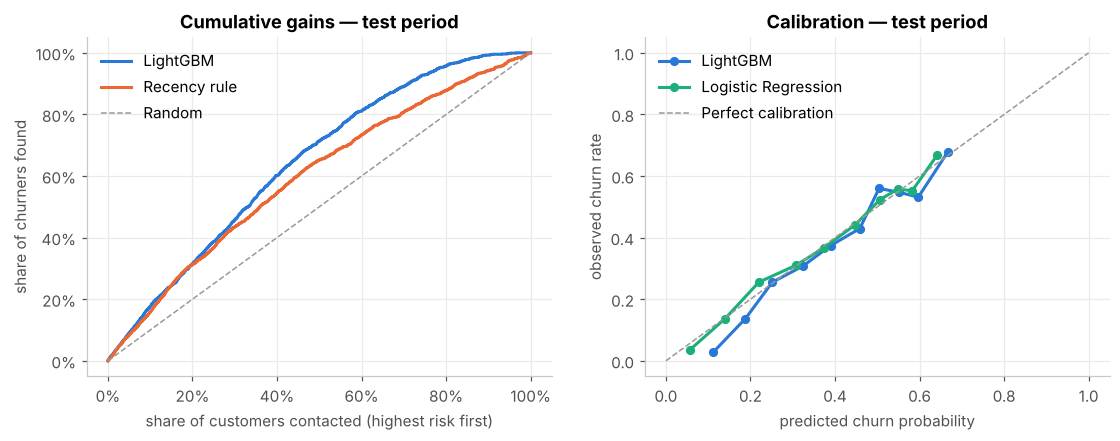

Mean predicted churn: 40.4% | actual churn rate: 38.5%


In [8]:
p_test = lgbm.predict_proba(X_test)[:, 1]
p_lr = logreg.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Cumulative gains
for name, s, c in [("LightGBM", p_test, BLUE), ("Recency rule", X_test.recency_days.values.astype(float), ORANGE)]:
    order = np.argsort(-s)
    gains = np.r_[0, np.cumsum(y_test.values[order]) / y_test.sum()]
    axes[0].plot(np.linspace(0, 1, len(gains)), gains, color=c, label=name)
axes[0].plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1, label="Random")
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].set_xlabel("share of customers contacted (highest risk first)"); axes[0].set_ylabel("share of churners found")
axes[0].set_title("Cumulative gains — test period"); axes[0].legend(frameon=False)

# Calibration
for name, p, c in [("LightGBM", p_test, BLUE), ("Logistic Regression", p_lr, AQUA)]:
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    axes[1].plot(mean_pred, frac_pos, marker="o", ms=5, color=c, label=name)
axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1, label="Perfect calibration")
axes[1].set_xlabel("predicted churn probability"); axes[1].set_ylabel("observed churn rate")
axes[1].set_title("Calibration — test period"); axes[1].legend(frameon=False)
fig.savefig(FIG / "03_gains_calibration.png"); plt.show()

print(f"Mean predicted churn: {p_test.mean():.1%} | actual churn rate: {y_test.mean():.1%}")

* **Gains:** contacting the riskiest 20% of customers by model score finds a much larger share of churners than
  the recency rule or random selection.
* **Calibration:** predicted probabilities track observed churn rates closely (and the average prediction is close
  to the real churn rate), so the probabilities can be used *as probabilities* — which the next section needs,
  because we multiply them by money.

## 5. Explainability — why is a customer at risk?

A churn score is only actionable if the account team knows *why*. SHAP values decompose each prediction into the
contribution of every feature (positive = pushes towards churn).

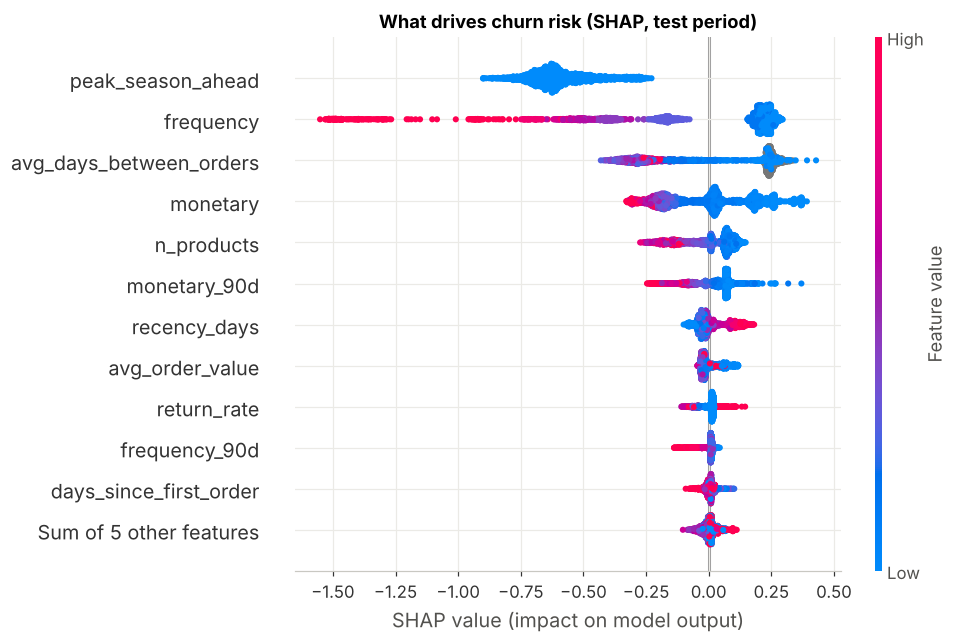

,logistic coefficient (standardised)
frequency,-0.508
peak_season_ahead,-0.417
frequency_90d,-0.340
avg_order_value,-0.312
days_since_first_order,-0.304
monetary_90d,-0.153
n_products,-0.079
monetary_30d,-0.043
avg_items_per_order,0.006
is_uk,0.017


In [9]:
explainer = shap.TreeExplainer(lgbm)
sv = explainer(X_test)
if sv.values.ndim == 3:          # some shap versions return one slice per class
    sv = sv[:, :, 1]
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("What drives churn risk (SHAP, test period)")
plt.savefig(FIG / "04_shap_summary.png"); plt.show()

coefs = pd.Series(logreg[-1].coef_[0], index=FEATURES).sort_values()
coefs.to_frame("logistic coefficient (standardised)")

**What the model learned:**

* **Seasonality** has the largest single effect: when the Q4 peak is ahead, risk drops for everyone (`peak_season_ahead`).
* **Order frequency is the strongest customer-level protector**: customers with many orders in the last 6 months rarely churn.
* **Single-order customers are at extra risk**: `avg_days_between_orders` is missing for them (grey points),
  and the model learned that "no second order yet" pushes risk up.
* **Breadth & value** (`n_products`, `monetary`) protect: broad, high-spend relationships are stickier.
* **High recency** and a **high return rate** push risk up — the customer is late, or unhappy.

A note on the logistic coefficients: several features are strongly correlated (e.g. `monetary` and `monetary_90d`),
so individual coefficients can take counter-intuitive signs. That's why SHAP on the final model, not raw
coefficients, is used to interpret drivers.

These translate directly into business language: *"this customer used to order every month, hasn't ordered in 70
days and their spend is falling"* is an explanation an account manager can act on.

## 6. From probabilities to decisions — value-based targeting

The model tells us **who** is likely to leave. The business question is **who is worth saving**.

* **Customer value (CLV proxy):** annualised revenue over the last 180 days. A simple, transparent proxy;
  a probabilistic model (BG/NBD + Gamma-Gamma) is a natural next step.
* **Expected revenue at risk = P(churn) × CLV.** This is what we rank customers by.

We compare four targeting strategies for a campaign that can contact **20% of the active base**, measuring the
share of *actually lost* customer value (the CLV of customers who really churned in the test window) that the
campaign reaches.

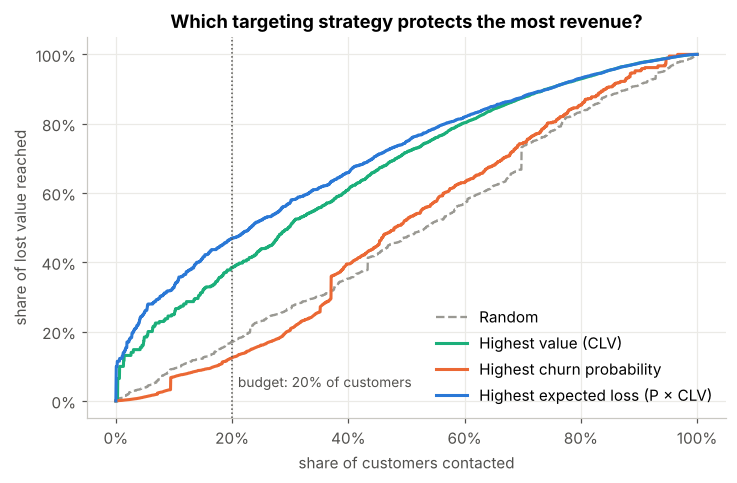

,customers contacted,actual churners reached,precision,lost value reached (£),share of lost value reached
Random,555.000,200.000,0.360,"213,441.739",0.170
Highest value (CLV),555.000,75.000,0.135,"481,839.440",0.385
Highest churn probability,555.000,338.000,0.609,"157,444.676",0.126
Highest expected loss (P × CLV),555.000,137.000,0.247,"587,347.679",0.469


In [10]:
scored = test[["CustomerID", "churn", "monetary", "recency_days", "frequency"]].copy()
scored["p_churn"] = p_test
scored["clv"] = scored.monetary * 365 / LOOKBACK
scored["expected_loss"] = scored.p_churn * scored.clv

STRATEGIES = {
    "Random": None,
    "Highest value (CLV)": "clv",
    "Highest churn probability": "p_churn",
    "Highest expected loss (P × CLV)": "expected_loss",
}
lost_value = scored.loc[scored.churn == 1, "clv"].sum()

def value_curve(col):
    s = scored.sample(frac=1, random_state=RANDOM_STATE) if col is None else scored.sort_values(col, ascending=False)
    captured = np.r_[0, np.cumsum(np.where(s.churn == 1, s.clv, 0))] / lost_value
    return np.linspace(0, 1, len(captured)), captured

fig, ax = plt.subplots(figsize=(7.5, 4.5))
colors = {"Random": GRAY, "Highest value (CLV)": AQUA, "Highest churn probability": ORANGE,
          "Highest expected loss (P × CLV)": BLUE}
for name, col in STRATEGIES.items():
    x, y = value_curve(col)
    ax.plot(x, y, color=colors[name], label=name, ls="--" if col is None else "-", lw=1.5 if col is None else 2)
ax.axvline(0.2, color=INK, lw=1, ls=":")
ax.text(0.21, 0.04, "budget: 20% of customers", color=INK, fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("share of customers contacted"); ax.set_ylabel("share of lost value reached")
ax.set_title("Which targeting strategy protects the most revenue?"); ax.legend(frameon=False, loc="lower right")
fig.savefig(FIG / "05_value_targeting.png"); plt.show()

K = int(len(scored) * 0.20)
rows = {}
for name, col in STRATEGIES.items():
    sel = scored.sample(K, random_state=RANDOM_STATE) if col is None else scored.nlargest(K, col)
    rows[name] = {"customers contacted": K, "actual churners reached": int(sel.churn.sum()),
                  "precision": sel.churn.mean(),
                  "lost value reached (£)": sel.loc[sel.churn == 1, "clv"].sum(),
                  "share of lost value reached": sel.loc[sel.churn == 1, "clv"].sum() / lost_value}
strategy_table = pd.DataFrame(rows).T
strategy_table

**This is the key result of the project.**

* Ranking by **churn probability** finds the most churners (~61% precision) — but they are mostly small, occasional
  buyers, so it reaches **even less lost value than random targeting** (~13% vs ~17%).
* Ranking by **value** alone does much better, but wastes contacts on big customers who were never going to leave.
* Ranking by **expected loss (P × CLV)** reaches **~47% of all lost value while contacting only 20% of customers** —
  almost **4× more** than the probability-only list with the same budget.

> *The best churn model is not the one with the highest AUC — it is the one whose output is combined with value
> to make the decision.*

### Campaign simulation — is it profitable, and how big should it be?

To turn this into money we need assumptions that, in a real project, would come from the client
(and ideally from an A/B test). They are explicit parameters so they can be challenged:

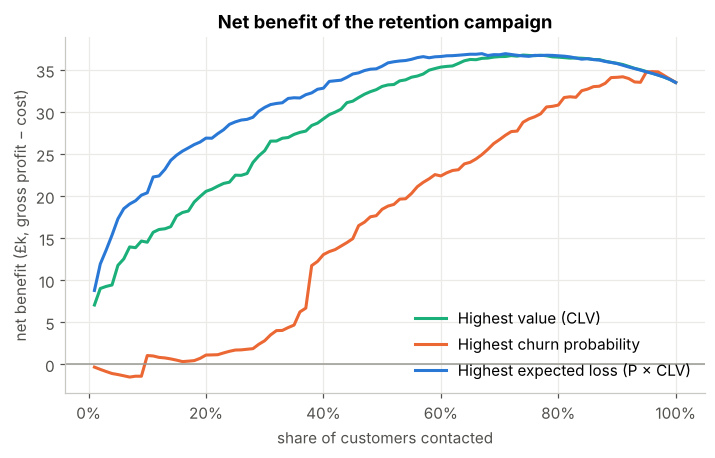

Net benefit contacting top 20%: £26,916 = 73% of the maximum (£36,956, reached contacting 67% of customers)


,save rate 10%,save rate 20%,save rate 30%
Highest value (CLV),"£6,130","£20,585","£35,041"
Highest churn probability,"£-3,602","£1,122","£5,845"
Highest expected loss (P × CLV),"£9,295","£26,916","£44,536"


In [11]:
COST_PER_CONTACT = 15.0   # £: account-manager call + incentive voucher
SAVE_RATE = 0.20          # share of targeted churners the campaign retains
MARGIN = 0.30             # gross margin on retained revenue

def net_benefit(col, frac, save_rate=SAVE_RATE):
    k = int(len(scored) * frac)
    sel = scored.nlargest(k, col)
    saved = save_rate * MARGIN * sel.loc[sel.churn == 1, "clv"].sum()
    return saved - COST_PER_CONTACT * k

fracs = np.linspace(0.01, 1, 100)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name, col in list(STRATEGIES.items())[1:]:
    nb = [net_benefit(col, f) / 1e3 for f in fracs]
    ax.plot(fracs, nb, color=colors[name], label=name)
best_frac = fracs[np.argmax([net_benefit("expected_loss", f) for f in fracs])]
ax.axhline(0, color=GRAY, lw=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("share of customers contacted"); ax.set_ylabel("net benefit (£k, gross profit − cost)")
ax.set_title("Net benefit of the retention campaign"); ax.legend(frameon=False)
fig.savefig(FIG / "06_campaign_net_benefit.png"); plt.show()

nb20, nb_best = net_benefit("expected_loss", 0.20), net_benefit("expected_loss", best_frac)
print(f"Net benefit contacting top 20%: £{nb20:,.0f} = {nb20 / nb_best:.0%} of the maximum (£{nb_best:,.0f}, "
      f"reached contacting {best_frac:.0%} of customers)")
sens = pd.DataFrame({f"save rate {r:.0%}": {name: net_benefit(col, 0.20, r) for name, col in list(STRATEGIES.items())[1:]}
                     for r in (0.10, 0.20, 0.30)})
sens.style.format("£{:,.0f}").set_caption("Net benefit of contacting the top 20%, by save-rate assumption")

* **Strong diminishing returns:** with the expected-loss ranking, the first 20% of contacts already deliver most of
  the achievable benefit; after that, each extra contact adds very little.
* The probability-only list barely breaks even until ~30–40% of the base is contacted.
* Under every save-rate assumption the expected-loss ranking is the most profitable. The exact £ figures depend on
  the assumptions; **the ranking of strategies does not.**

## 7. Segmentation & next best action

To make the output operational, each active customer is placed in a **risk × value** matrix (thresholds: churn
probability above the average churn rate; value = top 25% CLV) with one recommended action per segment.

In [12]:
high_value = scored.clv >= scored.clv.quantile(0.75)
RISK_THRESHOLD = scored.p_churn.mean()  # 'above-average risk'
high_risk = scored.p_churn >= RISK_THRESHOLD
scored["segment"] = np.select(
    [high_value & high_risk, high_value & ~high_risk, ~high_value & high_risk],
    ["1. Save now", "2. Protect & grow", "3. Automated win-back"], default="4. Business as usual")
ACTIONS = {
    "1. Save now": "Account-manager call + tailored offer within 2 weeks",
    "2. Protect & grow": "Loyalty programme, early access to Q4 catalogue, cross-sell",
    "3. Automated win-back": "Low-cost email sequence with time-limited discount",
    "4. Business as usual": "Standard newsletter; no incentive spend",
}
seg = scored.groupby("segment").agg(customers=("CustomerID", "size"), avg_p_churn=("p_churn", "mean"),
                                    actual_churn_rate=("churn", "mean"), avg_annual_value=("clv", "mean"),
                                    revenue_at_risk=("expected_loss", "sum"))
seg["share_of_revenue_at_risk"] = seg.revenue_at_risk / seg.revenue_at_risk.sum()
seg["share_of_value_actually_lost"] = (scored[scored.churn == 1].groupby("segment").clv.sum() / lost_value).reindex(seg.index)
seg["recommended action"] = seg.index.map(ACTIONS)
seg.style.format({"avg_p_churn": "{:.0%}", "actual_churn_rate": "{:.0%}", "avg_annual_value": "£{:,.0f}",
                  "revenue_at_risk": "£{:,.0f}", "share_of_revenue_at_risk": "{:.0%}",
                  "share_of_value_actually_lost": "{:.0%}"})

,customers,avg_p_churn,actual_churn_rate,avg_annual_value,revenue_at_risk,share_of_revenue_at_risk,share_of_value_actually_lost,recommended action
segment,,,,,,,,
1. Save now,64,48%,48%,"£6,135","£195,105",12%,20%,Account-manager call + tailored offer within 2 weeks
2. Protect & grow,630,18%,11%,"£8,002","£659,766",42%,24%,"Loyalty programme, early access to Q4 catalogue, cross-sell"
3. Automated win-back,1409,55%,54%,£625,"£450,681",29%,36%,Low-cost email sequence with time-limited discount
4. Business as usual,672,30%,31%,"£1,346","£259,304",17%,21%,Standard newsletter; no incentive spend


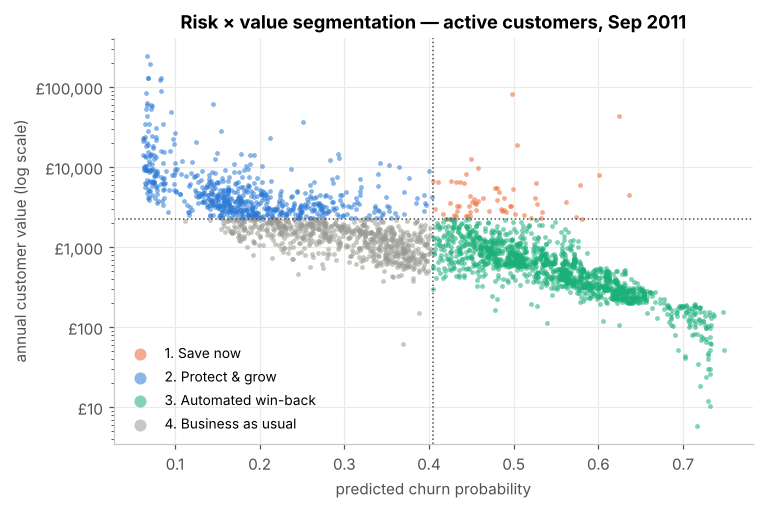

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
seg_colors = {"1. Save now": ORANGE, "2. Protect & grow": BLUE, "3. Automated win-back": AQUA, "4. Business as usual": GRAY}
for name, d in scored.groupby("segment"):
    ax.scatter(d.p_churn, d.clv, s=10, alpha=0.55, color=seg_colors[name], label=name, linewidths=0)
ax.set_yscale("log")
ax.axvline(RISK_THRESHOLD, color=INK, lw=1, ls=":"); ax.axhline(scored.clv.quantile(0.75), color=INK, lw=1, ls=":")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"£{v:,.0f}"))
ax.set_xlabel("predicted churn probability"); ax.set_ylabel("annual customer value (log scale)")
ax.set_title("Risk × value segmentation — active customers, Sep 2011")
ax.legend(frameon=False, markerscale=2.5, loc="lower left", fontsize=9)
fig.savefig(FIG / "07_risk_value_matrix.png"); plt.show()

## 8. Conclusions & recommendations

**For the business**

1. **Target by expected revenue at risk, not by churn probability.** Contacting 20% of customers ranked this way
   reaches ~47% of the value lost to churn — ~4× more than a probability-only list, which does worse than random.
2. **Prioritise the "Save now" segment** — 64 high-value, above-average-risk customers (~2% of the active base) account
   for ~20% of the value actually lost in the test quarter; this is where personal account-manager contact pays off.
3. **Use cheap, automated win-back for low-value at-risk customers**, and avoid spending incentives on customers who
   are not at risk.
4. **Time the campaign before Q4**: the September snapshot is the moment to act, ahead of the peak buying season.

**Limitations (and how I'd address them in a real project)**

* *Churn ≠ causality.* The model finds customers likely to leave, not customers whose behaviour *a campaign would change*.
  The next step is an **A/B test or uplift model** to measure incremental impact and the real save rate.
* *CLV is a proxy* (annualised recent revenue). A **BG/NBD + Gamma-Gamma** model would give a forward-looking CLV.
* *Only transactional data.* Adding marketing contacts, web behaviour, customer service tickets or product categories would likely improve the model.
* *Two years of data* means only two Q4 seasons; monitor performance and recalibrate quarterly once deployed.